In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
df = pd.read_csv('../data/processed.csv')

In [4]:
np.random.seed(42)

## 1. Извлекаем реальную сумму кредита и числа работников из логарифма

In [5]:
real_loan_amount = np.exp(df.loan_amount_rub)
real_employees = np.round(np.exp(df.employees_count)).astype(int)

## 2. Генерируем данные с учетом логики и корреляций

#### 2.1 ЕГРЮЛ/ЕГРИП

Возраст бизнеса связан со статусом кредита напрямую: чем моложе бизнес, тем выше риск дефолта

In [6]:
# создаем латентный фактор благонадежности компании (от 0 до 1), который будет управлять всеми корреляциями в данных (без прямой утечки целевого признака)
df['latent_risk_score'] = np.random.beta(5, 5, size=len(df)) # будем использовать его только там, где может появиться утечка целевой переменной

# чем выше latent_risk_score, тем в среднем старше и стабильнее бизнес
df['business_age_months'] = np.clip(
    (df['latent_risk_score'] * 120 + np.random.normal(20, 30, size=len(df))), 
    6, 300
).astype(int)


Категория риска по ОКВЭД: 1 - `низкий`, 2 - `средний`, 3 - `высокий`

In [7]:
df['okved_risk_level'] = np.random.choice([1, 2, 3], size=len(df), p=[0.6, 0.3, 0.1])

Уставный капитал (только для юр. лиц, т.е. `business_type == 1`, у ИП уставного капитала нет → 0)

In [8]:
df['authorized_capital'] = np.where(
    df.business_type == 1,
    np.random.choice([10000, 50000, 100000, 500000], size=len(df), p=[0.5, 0.3, 0.1, 0.1]), 0
)

#### 2.2 ФНС

Выручку за прошлый год логично привязать к размеру кредита и числу сотрудников (вырчка обычно в 1.5 -5 раз больше взятого кредита)

In [9]:
df['revenue_last_year'] = real_loan_amount * np.random.uniform(1.5, 5.0, size=len(df))

Тем роста выручки (в процентах) у дефолтных кампаний чаще падает

In [10]:
df['revenue_growth_rate'] = df['latent_risk_score'] * 20 - 5 + np.random.normal(0, 12, size=len(df))


Чистая прибыль (в процентах от выручки) обычно 5-25%, у дефолтных кампаний ниже

In [11]:
# Коэффициент маржинальности зависит от общего уровня стабильности компании
margin_coef = np.clip(
    (df['latent_risk_score'] * 0.15 - 0.02 + np.random.normal(0, 0.08, size=len(df))), 
    -0.20, 0.30
)
df['net_profit'] = df['revenue_last_year'] * margin_coef


У дефолтных кампаний вероятность недоимок по налогом обычно выше, чем у тех, кто выплатил кредит

In [12]:
# Чем ниже латентный скоринг, тем выше вероятность недоимки по налогам
tax_arrears_prob = 1 / (1 + np.exp(3 * df['latent_risk_score'] - 1))
df['has_tax_arrears'] = (np.random.rand(len(df)) < tax_arrears_prob).astype(int)


Аналогично с блокировкой счетов

In [13]:
# Аналогично для блокировки счетов — плавная вероятность вместо жесткого условия
blocked_prob = 1 / (1 + np.exp(3.5 * df['latent_risk_score'] - 1))
df['has_blocked_accounts'] = (np.random.rand(len(df)) < blocked_prob).astype(int)


#### 2.3 БКИ

Скоринг БКИ (300-850) у надеждных заемщиков выше

In [14]:
# Скоринг БКИ теперь напрямую отражает наш latent_risk_score с добавлением шума
df['bki_score'] = np.clip(
    (300 + df['latent_risk_score'] * 500 + np.random.normal(0, 50, size=len(df))), 
    300, 850
).astype(int)


Текущая долговая нагрузка связана с годовой выручкой (например, от 10 до 80% выручки)

In [15]:
df['current_debt_load'] = df['revenue_last_year'] * np.random.uniform(0.1, 0.8, size=len(df))

Максимальная просрочка в днях

In [16]:
# Распределяем просрочку в зависимости от непрерывного балла риска
def gen_delinquency(score):
    if score > 0.7:  # очень надежные
        return np.random.choice([0, 1, 3, 5, 10], p=[0.75, 0.15, 0.05, 0.03, 0.02])
    elif score > 0.4:  # средние
        return np.random.choice([0, 3, 5, 10, 20, 30, 60], p=[0.50, 0.15, 0.10, 0.10, 0.08, 0.05, 0.02])
    else:  # высокорисковые
        return np.random.choice([0, 5, 15, 30, 60, 90, 120, 180, 360], p=[0.12, 0.08, 0.10, 0.12, 0.15, 0.15, 0.12, 0.10, 0.06])

df['max_delinquency_days'] = df['latent_risk_score'].apply(gen_delinquency)


Количество действующих кредитов

In [17]:
df['active_credits_count'] = np.random.randint(0, 5, size=len(df))

#### 2.4 ФССП / Арбитраж

Сумма задолженности по ФССП у дефолтных кампаний выше

In [18]:
def gen_fssp(row):
    if row['latent_risk_score'] > 0.5:
        return np.random.choice([0, 5000, 15000, 50000], p=[0.85, 0.07, 0.05, 0.03])
    else:
        if np.random.random() < 0.35:
            return 0.0
        return round(row['revenue_last_year'] * np.random.uniform(0.02, 0.20), 2)

df['fssp_debt_amount'] = df.apply(gen_fssp, axis=1)


Количество судебных дел

In [19]:
# Количество судебных дел через Пуассона, где лямбда зависит от риска
lambda_lawsuits = 2.5 - (df['latent_risk_score'] * 2.0)
df['active_lawsuits_count'] = np.random.poisson(np.clip(lambda_lawsuits, 0.1, 5.0))


#### 2.5 Округлим денежные значения для красоты

In [20]:
money_cols = ['revenue_last_year', 'net_profit', 'current_debt_load', 'fssp_debt_amount']
df[money_cols] = df[money_cols].round(2)

#### 2.6 Цели кредита

1 - оборотные средства, 2 - инвестиции, 3 - рефинансирование, 4 - исполнение контрактов, 5 - рискованные цели.

In [21]:
purposes = ['working_capital', 'investment', 'refinancing', 'contract', 'risky']

def gen_purpose(score):
    if score > 0.5:
        return np.random.choice(purposes, p=[0.45, 0.20, 0.12, 0.15, 0.08])
    else:
        return np.random.choice(purposes, p=[0.35, 0.15, 0.18, 0.10, 0.22])

df['loan_purpose'] = df['latent_risk_score'].apply(gen_purpose)


#### 2.7 Структура владения

Категории структуры владения: 1 — одиночная МСБ, 2 — взаимосвязанная МСБ. У взаимосвязанной выше шанс одобрения кредита)

In [22]:
# Вероятность структуры владения также зависит от латентного фактора
ownership_prob = np.clip(0.35 + df['latent_risk_score'] * 0.3, 0.1, 0.9)
df['ownership_structure'] = np.where(np.random.rand(len(df)) < ownership_prob, 2, 1)


#### 2.8 Масштаб бизнеса

Уже есть признак `real_employees` отталкиваемся от него. Берём официальные границы МСБ по числу сотрудников: микро до 15, малый от 16 до 100, средний от 101 до 250

In [23]:
df['business_scale'] = np.select(
    [real_employees <= 15, real_employees <= 100],
    [1, 2],
    default=3
)

In [24]:
# Генерируем финальный лог-коэффициент на основе латентного фактора и ключевых метрик
# Добавляем случайный шум, чтобы симулировать непредсказуемость рынка
target_prob = 1 / (1 + np.exp(- (df['latent_risk_score'] * 6 - 3 + np.random.normal(0, 0.8, size=len(df)))))

# Определяем статус кредита (1 - выплачен, 0 - дефолт)
df['loan_status'] = (np.random.rand(len(df)) < target_prob).astype(int)

# Удаляем латентный фактор, чтобы он сам не протек в обучение
df.drop(columns=['latent_risk_score'], errors='ignore', inplace=True)


## 3. Посмотрим на созданные данные

In [25]:
df

,loan_term_months,employees_count,business_type,is_rev_line_of_loan,loan_amount_rub,loan_status,is_franchise,industry_sector,business_age_months,okved_risk_level,...,has_blocked_accounts,bki_score,current_debt_load,max_delinquency_days,active_credits_count,fssp_debt_amount,active_lawsuits_count,loan_purpose,ownership_structure,business_scale
0,84,1.609438,2,0,15.408819,0,0,45,86,2,...,0,529,9701361.15,0,1,0.00,0,investment,1,1
1,60,1.098612,2,0,15.003354,0,0,72,25,3,...,1,491,4295978.89,0,4,495362.57,3,working_capital,1,1
2,180,2.079442,1,0,16.973957,1,0,62,115,1,...,0,658,16789087.38,0,0,5000.00,3,working_capital,2,1
3,60,1.098612,1,0,14.869823,0,0,unknown,30,2,...,0,547,5384121.51,120,0,1695500.27,0,investment,2,1
4,240,2.708050,1,0,16.748197,1,0,unknown,118,1,...,1,608,4051225.57,1,1,50000.00,1,contract,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871002,60,1.945910,1,0,15.562970,0,0,45,141,1,...,0,596,11561432.27,30,4,0.00,0,working_capital,2,1
871003,60,1.945910,1,1,15.757126,0,0,45,59,1,...,1,617,5006052.56,0,4,0.00,0,working_capital,1,1
871004,108,3.295837,1,0,17.018257,0,0,33,54,2,...,0,420,53885681.00,90,2,2227499.96,0,working_capital,2,2
871005,60,1.945910,1,0,15.631963,0,0,unknown,76,1,...,0,469,12543716.85,5,0,0.00,1,investment,1,1


In [26]:
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', vmin=-1, vmax=1)

<Axes: >

['loan_term_months',
 'employees_count',
 'business_type',
 'is_rev_line_of_loan',
 'loan_amount_rub',
 'loan_status',
 'is_franchise',
 'industry_sector',
 'business_age_months',
 'okved_risk_level',
 'authorized_capital',
 'revenue_last_year',
 'revenue_growth_rate',
 'net_profit',
 'has_tax_arrears',
 'has_blocked_accounts',
 'bki_score',
 'current_debt_load',
 'max_delinquency_days',
 'active_credits_count',
 'fssp_debt_amount',
 'active_lawsuits_count',
 'loan_purpose',
 'ownership_structure',
 'business_scale']

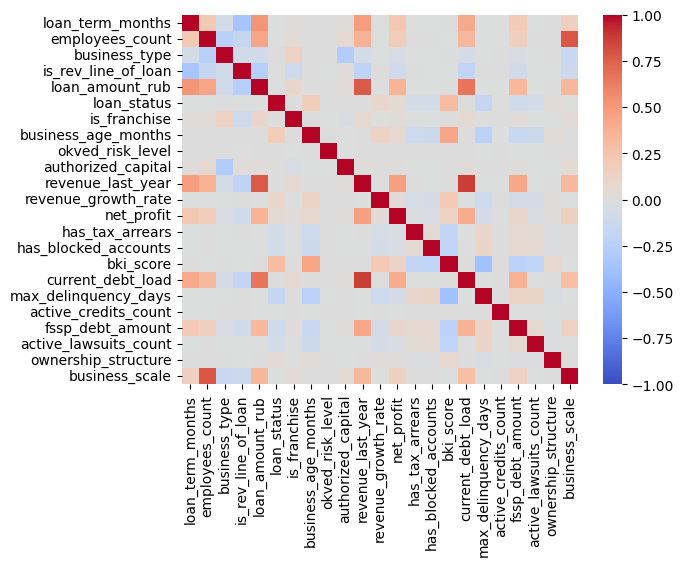

In [27]:
df.columns.to_list()

In [28]:
df = df[['loan_term_months',
 'employees_count',
 'business_type',
 'is_rev_line_of_loan',
 'loan_amount_rub',
 'is_franchise',
 'industry_sector',
 'business_age_months',
 'okved_risk_level',
 'authorized_capital',
 'revenue_last_year',
 'revenue_growth_rate',
 'net_profit',
 'has_tax_arrears',
 'has_blocked_accounts',
 'bki_score',
 'current_debt_load',
 'max_delinquency_days',
 'active_credits_count',
 'fssp_debt_amount',
 'active_lawsuits_count',
 'loan_purpose',
 'ownership_structure',
 'business_scale',
 'loan_status']]
df

,loan_term_months,employees_count,business_type,is_rev_line_of_loan,loan_amount_rub,is_franchise,industry_sector,business_age_months,okved_risk_level,authorized_capital,...,bki_score,current_debt_load,max_delinquency_days,active_credits_count,fssp_debt_amount,active_lawsuits_count,loan_purpose,ownership_structure,business_scale,loan_status
0,84,1.609438,2,0,15.408819,0,45,86,2,0,...,529,9701361.15,0,1,0.00,0,investment,1,1,0
1,60,1.098612,2,0,15.003354,0,72,25,3,0,...,491,4295978.89,0,4,495362.57,3,working_capital,1,1,0
2,180,2.079442,1,0,16.973957,0,62,115,1,10000,...,658,16789087.38,0,0,5000.00,3,working_capital,2,1,1
3,60,1.098612,1,0,14.869823,0,unknown,30,2,50000,...,547,5384121.51,120,0,1695500.27,0,investment,2,1,0
4,240,2.708050,1,0,16.748197,0,unknown,118,1,100000,...,608,4051225.57,1,1,50000.00,1,contract,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871002,60,1.945910,1,0,15.562970,0,45,141,1,10000,...,596,11561432.27,30,4,0.00,0,working_capital,2,1,0
871003,60,1.945910,1,1,15.757126,0,45,59,1,50000,...,617,5006052.56,0,4,0.00,0,working_capital,1,1,0
871004,108,3.295837,1,0,17.018257,0,33,54,2,50000,...,420,53885681.00,90,2,2227499.96,0,working_capital,2,2,0
871005,60,1.945910,1,0,15.631963,0,unknown,76,1,10000,...,469,12543716.85,5,0,0.00,1,investment,1,1,0


In [29]:
df.to_csv('../data/feautred.csv', index=False)